# <span style="color:darkblue"> Lecture 13a: Regression Trees
 </span>

<font size = "5">



<font size = "5">

Install the "graphviz" library. In the terminal:

```pip install graphviz``` (Visualize regression trees) <br>
```pip install ISLP```     (Data from Intro to Statistical Learning)

If the Graphviz is not working

``` conda install python-graphviz ```

# <span style="color:darkblue"> I. Setup Working Environment </span>


In [2]:
# The "pandas" library is used for processing datasets
# The "numpy" is for numeric observations and random numbers
# The "matplotlib.pyplot" library is for creating graphs

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# We will use the "sklearn" package

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor as DTR
from sklearn import tree
import sklearn.model_selection as skm
from sklearn.ensemble import RandomForestRegressor as RF


# This is used to create data matrices
import patsy

# This is used to visualize regreesion trees
# Tree visualization uses sklearn.tree.plot_tree; graphviz is not required.

# Import content from the book "Introduction to Statistical Learning"
import ISLP


# <span style="color:darkblue"> II. Mashable Dataset </span>


<font size = "5">

Mashable is a news website, digital media platform <br> 
and entertainment company. Our goal will be to predict which articles <br>
get shared most often. We will be working with a subset of the data <br>
compiled by the following authors:

Original Article <br>
https://repositorium.sdum.uminho.pt/bitstream/1822/39169/1/main.pdf

The Kaggle data repository <br>
https://www.kaggle.com/datasets/thehapyone/uci-online-news-popularity-data-set


In [3]:
articles_train  = pd.read_csv("data_raw/ArticlesTrain.csv")
articles_test   = pd.read_csv("data_raw/ArticlesTest.csv")


<font size = "5">

Create features matrix ($X$) and labels/outcomes $(Y)$


In [4]:
# Extract all columns except "shares" (the outcome)
X_train = articles_train.drop(columns = ["shares"])
X_test  = articles_test.drop(columns = ["shares"])

# Extract shares (the outcome)
y_train = articles_train[["shares"]]
y_test = articles_test[["shares"]]

<font size = "5">

Train regression tree

- Compute $\widehat{f}(x)$
- Random state sets a seed for tie breaking

In [5]:
tree_model = DTR(max_depth=3,random_state = 0) 
tree_model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=3, random_state=0)

<font size = "5">

Evaluate out-of-sample mean squared error (MSE)

- $\mathcal{I}_{train}\quad$  (training data)
- $\mathcal{I}_{test}\quad$ (test data)

$ MSE = \frac{1}{n_{test}}\sum_{i \in \mathcal{I}_{test}} (y_i - \widehat{f}(X_i))^2 $

In [6]:
# Convert y_test to array for comparison
y_test_array = (np.array(y_test))

# Compute MSE
np.mean((y_test_array- tree_model.predict(X_test))**2)

np.float64(0.7286472382489183)

<font size = "5">

Display Tree

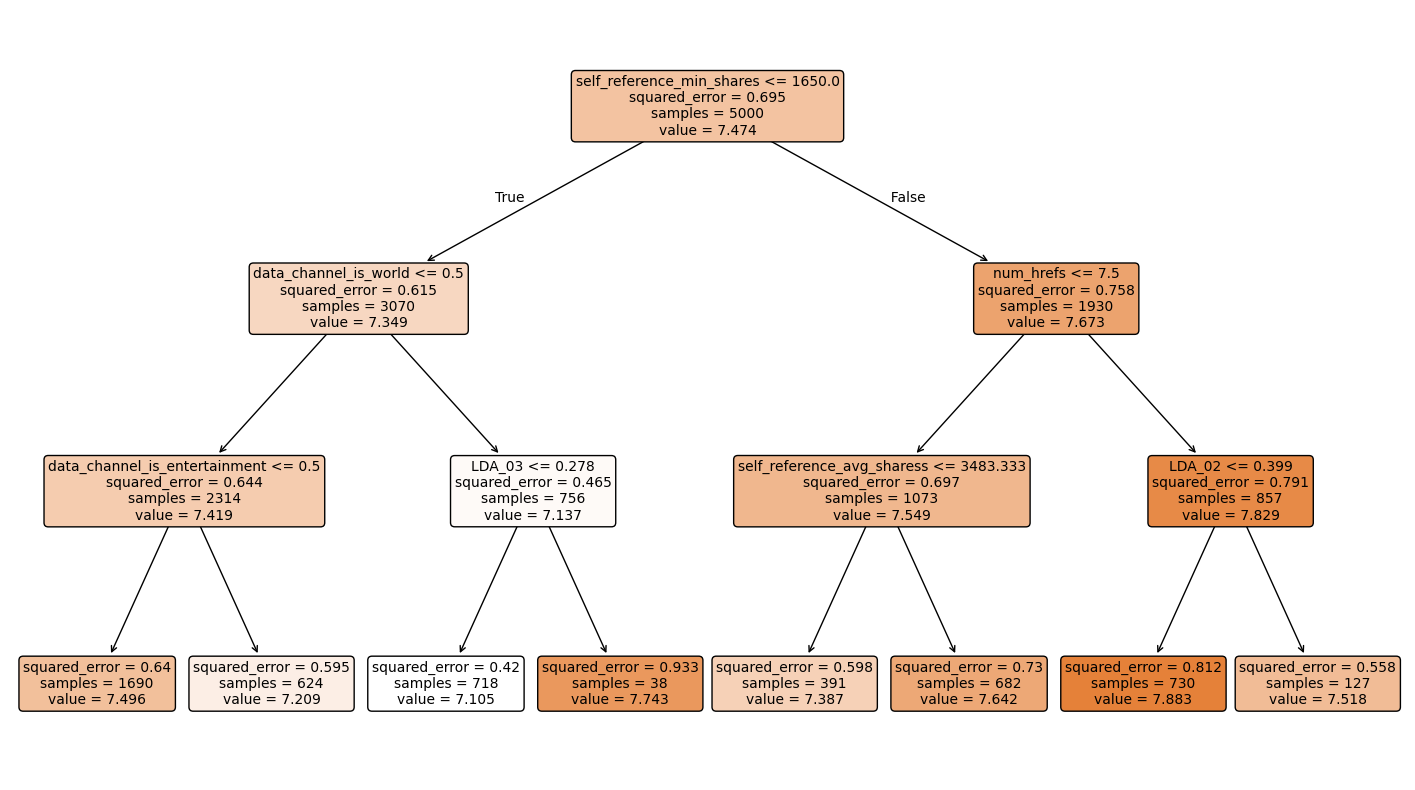

In [7]:
plt.figure(figsize=(18, 10))

tree.plot_tree(
    tree_model,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

<font size = "5">

Cost Complexity Pruning (CCP)

- Depends on a tuning parameter (ccp)
- We split training data into folds to compute the <br>
optimal CCP parameter


In [8]:
ccp_path = tree_model.cost_complexity_pruning_path(X_train, y_train) 

kfold = skm.KFold(5,
                  shuffle=True,
                  random_state=10) 

grid = skm.GridSearchCV(tree_model,
                        {'ccp_alpha': ccp_path.ccp_alphas},
                        refit=True,
                        cv=kfold, 
                        scoring='neg_mean_squared_error')

G = grid.fit(X_train, y_train)

In [9]:
pruned_tree = grid.best_estimator_
np.mean((np.array(y_test) - pruned_tree.predict(X_test))**2)

np.float64(0.7286472382489183)

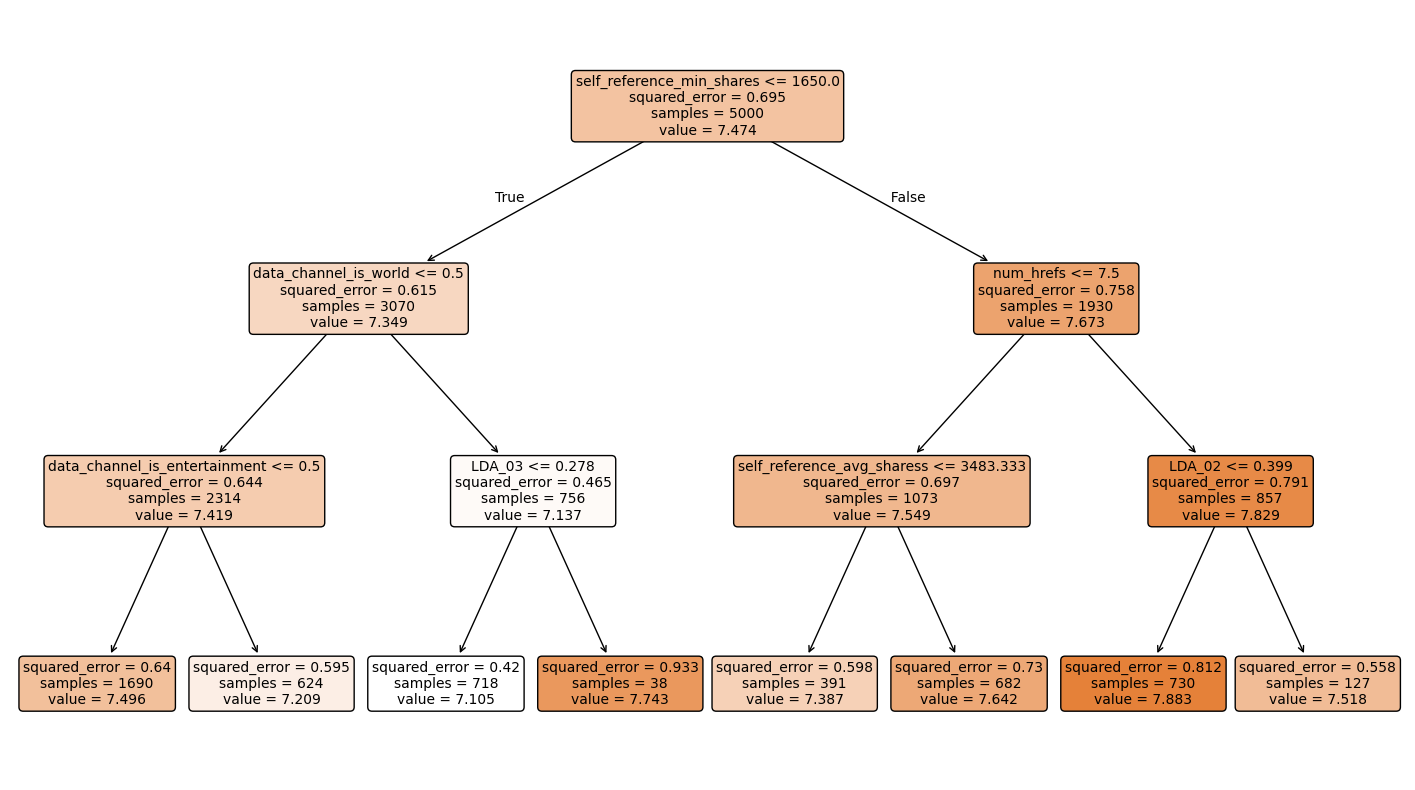

In [10]:
plt.figure(figsize=(18, 10))

tree.plot_tree(
    pruned_tree,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

# <span style="color:darkblue"> IV. Exercises </span>


<font size = "5">

Try it yourself!

For this exercises we will be working with a <br>
A data set containing housing values in 506 suburbs of Boston

In [11]:
Boston =  ISLP.load_data("Boston")

<font size = "5">

(a) Run a regression tree to predict the "crim" (crime) variable <br>
using all other neighborhood information, prune the tree, <br>
and report out-of-sample MSE

- Use two different tree depths. How does this affect <br>
out-of-sample performance?

In [13]:
boston_X = Boston.drop(columns="crim")
boston_y = Boston["crim"]

boston_X_train, boston_X_test, boston_y_train, boston_y_test = train_test_split(
    boston_X, boston_y, test_size=0.25, random_state=10
)

results = []

for depth in (2, 5):
    base_tree = DTR(max_depth=depth, random_state=0)
    ccp_path = base_tree.cost_complexity_pruning_path(
        boston_X_train, boston_y_train
    )

    search = skm.GridSearchCV(
        base_tree,
        {"ccp_alpha": ccp_path.ccp_alphas},
        cv=kfold,
        scoring="neg_mean_squared_error",
        refit=True
    )
    search.fit(boston_X_train, boston_y_train)

    test_mse = np.mean(
        (boston_y_test - search.best_estimator_.predict(boston_X_test)) ** 2
    )
    results.append({
        "max_depth": depth,
        "best_ccp_alpha": search.best_params_["ccp_alpha"],
        "test_MSE": test_mse
    })

pd.DataFrame(results)



,max_depth,best_ccp_alpha,test_MSE
0,2,0.0000,12.41787
1,5,5.7084,12.41787


<font size = "5">

(b) Run a linear regression using the same data. <br>
Which method has the lowest out-of-sample MSE? 

In [14]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(boston_X_train, boston_y_train)

linear_mse = np.mean(
    (boston_y_test - linear_model.predict(boston_X_test)) ** 2
)

comparison = pd.DataFrame([
    {"method": "Linear regression", "test_MSE": linear_mse},
    {"method": "Pruned tree, depth 2", "test_MSE": results[0]["test_MSE"]},
    {"method": "Pruned tree, depth 5", "test_MSE": results[1]["test_MSE"]},
])

comparison


,method,test_MSE
0,Linear regression,18.767155
1,"Pruned tree, depth 2",12.417870
2,"Pruned tree, depth 5",12.417870
